In [1]:
import time
from collections.abc import Callable
from datetime import datetime
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR10

from mlkit.blocks.embeddings import TimeEmbeddingConfig
from mlkit.blocks.unet import UNetBlockConfig
from mlkit.core.callbacks import MLflowLogger, ModelCheckpoint, ProgressLogger
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.metrics.collections import image_metrics
from mlkit.models.unet import UNet, UNetConfig
from mlkit.tasks.diffusion import DiffusionTask, LinearSchedule, NoiseSchedule
from mlkit.utils.device import get_device
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.utils.tracking import flatten_params, setup_mlflow
from mlkit.visual.curves import plot_history
from mlkit.visual.images import plot_image_grid
from mlkit.visual.samples import SampleGrid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

import mlflow

setup_logging()
use_style()

ROOT = Path("../..")
DATA_DIR = ROOT / "datasets/raw"
setup_mlflow(ROOT, "cgw_task_b")

SEED = 42
IMAGE_SHAPE = (3, 32, 32)
ANIMAL_CLASSES = ("bird", "cat", "deer", "dog", "frog", "horse")
VAL_FRACTION = 0.1

STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02
VARIANCE = "posterior"

IMAGE_INDEX = 7
NOISY_STEPS = (100, 250, 500, 750, 999)
MANUAL_STEP = 500
MANUAL_PIXEL = (0, 16, 16)
PREDICTION_ERRORS = (0.0, 0.1, 0.5)
CHAIN_STEPS = (999, 750, 500, 250, 100)

CHANNELS = (64, 128, 256)
DROPOUT = 0.1
EMBEDDING_DIM = 64
TIME_DIM = 256

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 2e-4
SAMPLE_EVERY = 5
NUM_SAMPLES = 16

NUM_GENERATED = 32
GENERATION_SHOWN = 4
RESTORE_STEPS = (100, 250, 500, 750)
RESTORE_SHOWN = 6
RESTORE_EVAL = 256

seed_everything(SEED)
device = get_device()

RUN_NAME = f"task_b_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

In [2]:
train_raw = CIFAR10(DATA_DIR, train=True, download=True)
test_raw = CIFAR10(DATA_DIR, train=False, download=True)
animal_labels = {train_raw.class_to_idx[name] for name in ANIMAL_CLASSES}


def to_model_range(data: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(data).permute(0, 3, 1, 2).float() / 127.5 - 1


def to_display(x: torch.Tensor) -> torch.Tensor:
    return ((x + 1) / 2).clamp(0, 1).cpu()


def animal_subset(dataset: CIFAR10) -> tuple[torch.Tensor, list[int]]:
    indices = [index for index, label in enumerate(dataset.targets) if label in animal_labels]
    return to_model_range(dataset.data[indices]), [dataset.targets[index] for index in indices]


train_images, train_targets = animal_subset(train_raw)
test_images, _ = animal_subset(test_raw)
fit_indices, val_indices = StratifiedSplitter((1 - VAL_FRACTION, VAL_FRACTION), seed=SEED).split(train_targets)
fit_images, val_images = train_images[fit_indices], train_images[val_indices]

train_loader = DataLoader(fit_images, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=True)
val_loader = DataLoader(val_images, batch_size=2 * BATCH_SIZE, pin_memory=True)
test_loader = DataLoader(test_images, batch_size=2 * BATCH_SIZE, pin_memory=True)

image_class = train_raw.classes[train_raw.targets[IMAGE_INDEX]]
if image_class not in ANIMAL_CLASSES:
    raise ValueError(f"IMAGE_INDEX must point to one of {ANIMAL_CLASSES}, got {IMAGE_INDEX} ({image_class})")
x0 = to_model_range(train_raw.data[IMAGE_INDEX : IMAGE_INDEX + 1])

print(f"Animals: train {len(fit_images)} | val {len(val_images)} | test {len(test_images)} | image {tuple(fit_images.shape[1:])}")
print(f"Range: [{fit_images.min().item():.1f}, {fit_images.max().item():.1f}] | x0: {image_class}, shape {tuple(x0.shape)}")

Animals: train 27000 | val 3000 | test 6000 | image (3, 32, 32)
Range: [-1.0, 1.0] | x0: horse, shape (1, 3, 32, 32)


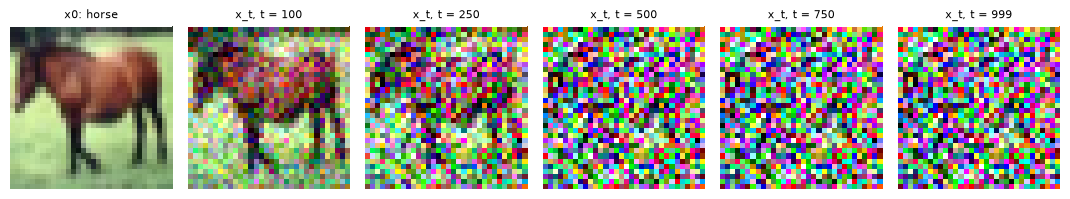

In [3]:
schedule = NoiseSchedule(STEPS, LinearSchedule(BETA_START, BETA_END))
eps = torch.randn(x0.shape, generator=torch.Generator().manual_seed(SEED))

repeated = x0.expand(len(NOISY_STEPS), -1, -1, -1)
noisy = schedule.add_noise(repeated, torch.tensor(NOISY_STEPS), eps.expand_as(repeated))
titles = [f"x0: {image_class}"] + [f"x_t, t = {step}" for step in NOISY_STEPS]
saver.save(plot_image_grid(to_display(torch.cat([x0, noisy])), titles, ncols=len(titles)), "x0_and_noisy");

In [4]:
x_t = schedule.add_noise(x0, torch.tensor([MANUAL_STEP]), eps)
z = torch.randn(x0.shape, generator=torch.Generator().manual_seed(SEED + 1))
variances = {"beta": schedule.betas, "posterior": schedule.posterior_variance}

beta = schedule.betas[MANUAL_STEP].item()
alpha = schedule.alphas[MANUAL_STEP].item()
alpha_bar = schedule.alpha_bars[MANUAL_STEP].item()
alpha_bar_prev = schedule.alpha_bars_prev[MANUAL_STEP].item()
sigma = np.sqrt(variances[VARIANCE][MANUAL_STEP].item())

x0_pixel = x0[0, *MANUAL_PIXEL].item()
x_t_pixel = x_t[0, *MANUAL_PIXEL].item()
eps_pixel = eps[0, *MANUAL_PIXEL].item()
z_pixel = z[0, *MANUAL_PIXEL].item()

eps_coef = beta / np.sqrt(1 - alpha_bar)
mean = (x_t_pixel - eps_coef * eps_pixel) / np.sqrt(alpha)
x_prev = mean + sigma * z_pixel
library_pixel = schedule.step(x_t, MANUAL_STEP, eps, z, VARIANCE)[0, *MANUAL_PIXEL].item()

print(f"t = {MANUAL_STEP}: beta = {beta:.6f} | alpha = {alpha:.6f} | alpha_bar = {alpha_bar:.6f} | alpha_bar_prev = {alpha_bar_prev:.6f}")
print(f"sigma_t ({VARIANCE} variance) = {sigma:.6f}")
print(f"Pixel {MANUAL_PIXEL}: x0 = {x0_pixel:.4f} | x_t = {x_t_pixel:.4f} | eps_pred = {eps_pixel:.4f} | z = {z_pixel:.4f}")
print(f"beta / sqrt(1 - alpha_bar) = {beta:.6f} / {np.sqrt(1 - alpha_bar):.6f} = {eps_coef:.6f}")
print(f"mean = (x_t - {eps_coef:.6f} * eps_pred) / sqrt(alpha) = ({x_t_pixel:.4f} - {eps_coef * eps_pixel:.4f}) / {np.sqrt(alpha):.6f} = {mean:.4f}")
print(f"x_(t-1) = mean + sigma * z = {mean:.4f} + {sigma:.6f} * {z_pixel:.4f} = {x_prev:.4f}")
print(f"NoiseSchedule.step: {library_pixel:.4f}")

records = []
for error in PREDICTION_ERRORS:
    eps_pred = eps_pixel + error
    x0_hat = (x_t_pixel - np.sqrt(1 - alpha_bar) * eps_pred) / np.sqrt(alpha_bar)
    records.append({
        "error in eps_pred": error,
        "eps_pred": eps_pred,
        "x0_hat": x0_hat,
        "x0_hat - x0": x0_hat - x0_pixel,
        "mean of x_(t-1)": (x_t_pixel - eps_coef * eps_pred) / np.sqrt(alpha),
    })
pd.DataFrame(records).set_index("error in eps_pred").round(4)

t = 500: beta = 0.010060 | alpha = 0.989940 | alpha_bar = 0.077797 | alpha_bar_prev = 0.078587
sigma_t (posterior variance) = 0.100256
Pixel (0, 16, 16): x0 = 0.1686 | x_t = 1.3376 | eps_pred = 1.3439 | z = 0.3661
beta / sqrt(1 - alpha_bar) = 0.010060 / 0.960314 = 0.010476
mean = (x_t - 0.010476 * eps_pred) / sqrt(alpha) = (1.3376 - 0.0141) / 0.994957 = 1.3302
x_(t-1) = mean + sigma * z = 1.3302 + 0.100256 * 0.3661 = 1.3669
NoiseSchedule.step: 1.3669


,eps_pred,x0_hat,x0_hat - x0,mean of x_(t-1)
error in eps_pred,,,,
0.0,1.3439,0.1686,0.0000,1.3302
0.1,1.4439,-0.1757,-0.3443,1.3291
0.5,1.8439,-1.5529,-1.7215,1.3249


,ideal eps: mse to x0
t = 999,0.18560
t = 750,0.17608
t = 500,0.15996
t = 250,0.09228
t = 100,0.02461
x0 (result),0.00000


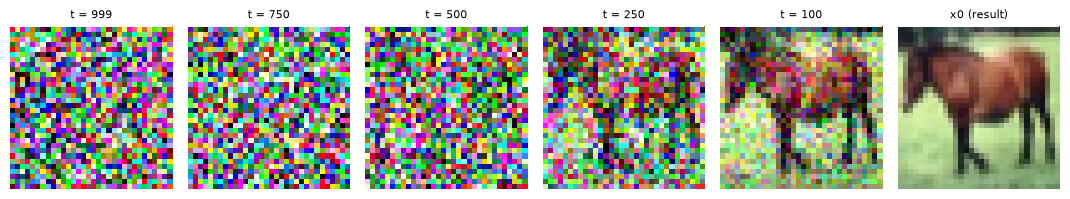

In [5]:
def reverse_chain(
    schedule: NoiseSchedule,
    x_t: torch.Tensor,
    start: int,
    predict_eps: Callable[[torch.Tensor, int], torch.Tensor],
    generator: torch.Generator,
) -> tuple[dict[int, torch.Tensor], torch.Tensor]:
    states: dict[int, torch.Tensor] = {}
    x = x_t
    for t in range(start, -1, -1):
        if t in CHAIN_STEPS:
            states[t] = x
        noise = None if t == 0 else torch.randn(x.shape, generator=generator).to(x.device)
        x = schedule.step(x, t, predict_eps(x, t), noise, VARIANCE)
    return states, x


def oracle_eps(schedule: NoiseSchedule, x0: torch.Tensor) -> Callable[[torch.Tensor, int], torch.Tensor]:
    def predict(x_t: torch.Tensor, t: int) -> torch.Tensor:
        alpha_bar = schedule.alpha_bars[t]
        return (x_t - torch.sqrt(alpha_bar) * x0) / torch.sqrt(1 - alpha_bar)

    return predict


def mse(x: torch.Tensor, target: torch.Tensor) -> float:
    return torch.mean((to_display(x) - to_display(target)) ** 2).item()


def chain_row(states: dict[int, torch.Tensor], final: torch.Tensor) -> torch.Tensor:
    return torch.cat([*(states[t] for t in CHAIN_STEPS), final]).cpu()


chain_titles = [f"t = {t}" for t in CHAIN_STEPS] + ["x0 (result)"]
x_T = schedule.add_noise(x0, torch.tensor([STEPS - 1]), eps)
oracle_states, oracle_final = reverse_chain(
    schedule, x_T, STEPS - 1, oracle_eps(schedule, x0), torch.Generator().manual_seed(SEED + 2)
)

saver.save(
    plot_image_grid(to_display(chain_row(oracle_states, oracle_final)), chain_titles, ncols=len(chain_titles)),
    "reverse_ideal_eps",
)
pd.DataFrame(
    {"ideal eps: mse to x0": [mse(oracle_states[t], x0) for t in CHAIN_STEPS] + [mse(oracle_final, x0)]},
    index=chain_titles,
).round(5)

In [6]:
config = UNetConfig(
    in_channels=IMAGE_SHAPE[0],
    input_size=IMAGE_SHAPE[1:],
    blocks=tuple(UNetBlockConfig(channels, dropout=DROPOUT) for channels in CHANNELS),
    time=TimeEmbeddingConfig(EMBEDDING_DIM, TIME_DIM),
)

seed_everything(SEED)
task = DiffusionTask(
    model=UNet(config),
    optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE),
    schedule=NoiseSchedule(STEPS, LinearSchedule(BETA_START, BETA_END)),
    image_shape=IMAGE_SHAPE,
    variance=VARIANCE,
    metrics=image_metrics(),
)

print(f"Parameters: {sum(p.numel() for p in task.model.parameters()):,}")
print("Output:", tuple(task.model(torch.zeros(2, *IMAGE_SHAPE), torch.zeros(2, dtype=torch.long)).shape))

Parameters: 2,908,035
Output: (2, 3, 32, 32)


Epoch 1 | train/loss 0.1355 val/loss 0.06033 val/mse 0.1057 val/psnr 14.24 val/ssim 0.2681 | 50.4s
Epoch 2 | train/loss 0.05917 val/loss 0.05089 val/mse 0.08603 val/psnr 15.1 val/ssim 0.2913 | 32.4s
Epoch 3 | train/loss 0.05196 val/loss 0.04457 val/mse 0.08331 val/psnr 15.28 val/ssim 0.2905 | 32.4s
Epoch 4 | train/loss 0.04812 val/loss 0.04468 val/mse 0.07963 val/psnr 15.84 val/ssim 0.3121 | 32.0s
Epoch 5 | train/loss 0.04537 val/loss 0.03808 val/mse 0.07569 val/psnr 15.71 val/ssim 0.3043 | 31.9s
Epoch 6 | train/loss 0.04379 val/loss 0.03996 val/mse 0.07828 val/psnr 15.87 val/ssim 0.3231 | 43.2s
Epoch 7 | train/loss 0.04211 val/loss 0.03803 val/mse 0.06658 val/psnr 16.29 val/ssim 0.3208 | 32.7s
Epoch 8 | train/loss 0.04065 val/loss 0.03794 val/mse 0.07022 val/psnr 16.05 val/ssim 0.3244 | 31.7s
Epoch 9 | train/loss 0.03973 val/loss 0.04199 val/mse 0.06877 val/psnr 16.6 val/ssim 0.3518 | 31.8s
Epoch 10 | train/loss 0.03945 val/loss 0.03626 val/mse 0.06365 val/psnr 16.51 val/ssim 0.3377 |

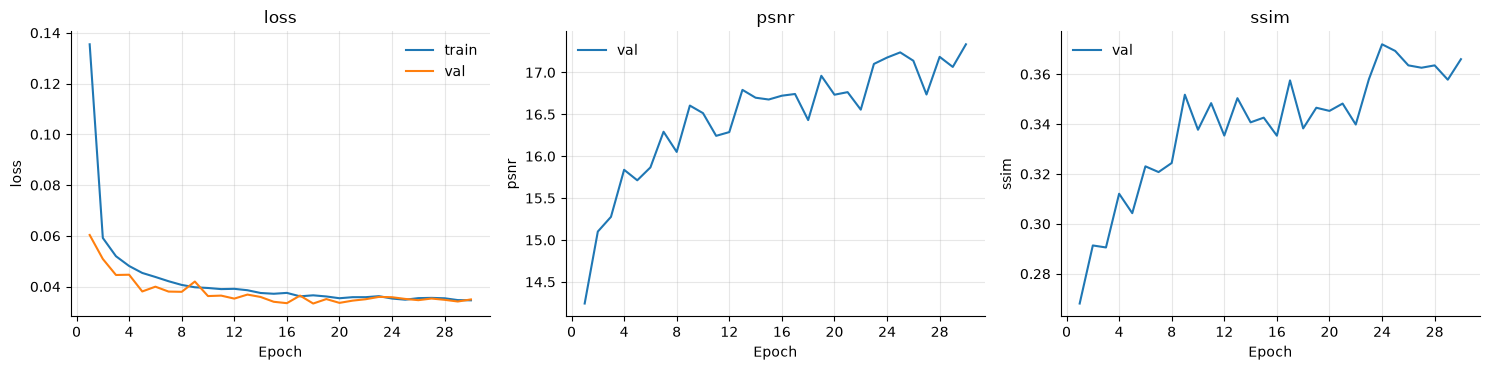

In [7]:
sample_z = torch.randn(NUM_SAMPLES, *IMAGE_SHAPE, generator=torch.Generator().manual_seed(SEED))

with mlflow.start_run(run_name=RUN_NAME):
    mlflow.log_params(
        flatten_params(config)
        | {
            "classes": ",".join(ANIMAL_CLASSES),
            "schedule": "linear",
            "steps": STEPS,
            "beta_start": BETA_START,
            "beta_end": BETA_END,
            "variance": VARIANCE,
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
        }
    )
    trainer = Trainer(device=device, callbacks=[
        ProgressLogger(),
        MLflowLogger(),
        ModelCheckpoint(task, monitor="val/loss", mode="min"),
        SampleGrid(
            lambda: task.generate(z=sample_z, generator=torch.Generator().manual_seed(SEED)),
            FigureSaver(saver.directory / "samples"),
            every=SAMPLE_EVERY,
        ),
    ])
    start = time.perf_counter()
    history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)
    train_seconds = time.perf_counter() - start

    seed_everything(SEED)
    test = trainer.evaluate(task, test_loader)
    mlflow.log_metrics({f"test/{key}": value for key, value in test.items()} | {"train_seconds": train_seconds})

task.eval()
torch.save(task.model.state_dict(), saver.directory / "unet.pt")
print(f"Training: {train_seconds / 60:.1f} min | test: " + " | ".join(f"{key} {value:.4f}" for key, value in test.items()))
saver.save(plot_history(history, ["loss", "psnr", "ssim"]), "training");

,ideal eps: mse to x0,U-Net: mse to x0
t = 999,0.18560,0.18560
t = 750,0.17608,0.17932
t = 500,0.15996,0.18106
t = 250,0.09228,0.16394
t = 100,0.02461,0.13690
x0 (result),0.00000,0.12707


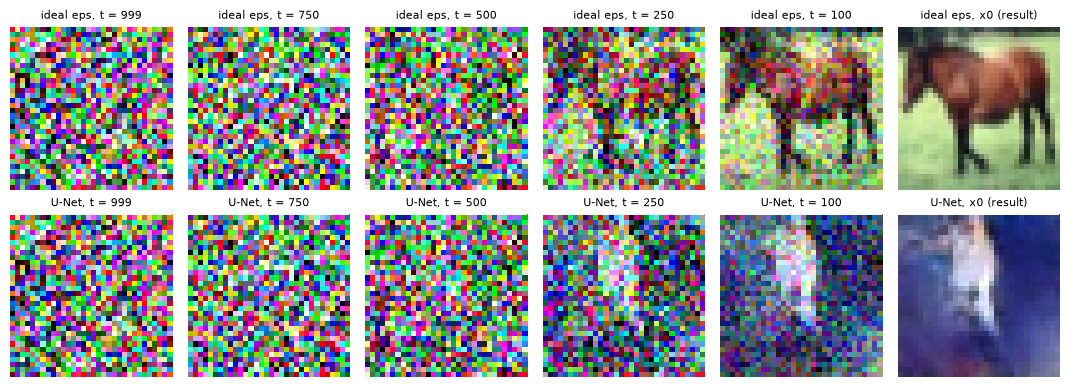

In [8]:
def model_eps(model: nn.Module) -> Callable[[torch.Tensor, int], torch.Tensor]:
    @torch.no_grad()
    def predict(x_t: torch.Tensor, t: int) -> torch.Tensor:
        steps = torch.full((x_t.size(0),), t, dtype=torch.long, device=x_t.device)
        prediction: torch.Tensor = model(x_t, steps)
        return prediction

    return predict


model_states, model_final = reverse_chain(
    task.schedule, x_T.to(device), STEPS - 1, model_eps(task.model), torch.Generator().manual_seed(SEED + 2)
)

rows = torch.cat([chain_row(oracle_states, oracle_final), chain_row(model_states, model_final)])
titles = [f"ideal eps, {title}" for title in chain_titles] + [f"U-Net, {title}" for title in chain_titles]
saver.save(plot_image_grid(to_display(rows), titles, ncols=len(chain_titles)), "reverse_ideal_vs_unet")

pd.DataFrame(
    {
        "ideal eps: mse to x0": [mse(oracle_states[t], x0) for t in CHAIN_STEPS] + [mse(oracle_final, x0)],
        "U-Net: mse to x0": [mse(model_states[t], x0) for t in CHAIN_STEPS] + [mse(model_final, x0)],
    },
    index=chain_titles,
).round(5)

Generated 32 images in 12.5s | 1000 U-Net passes per image


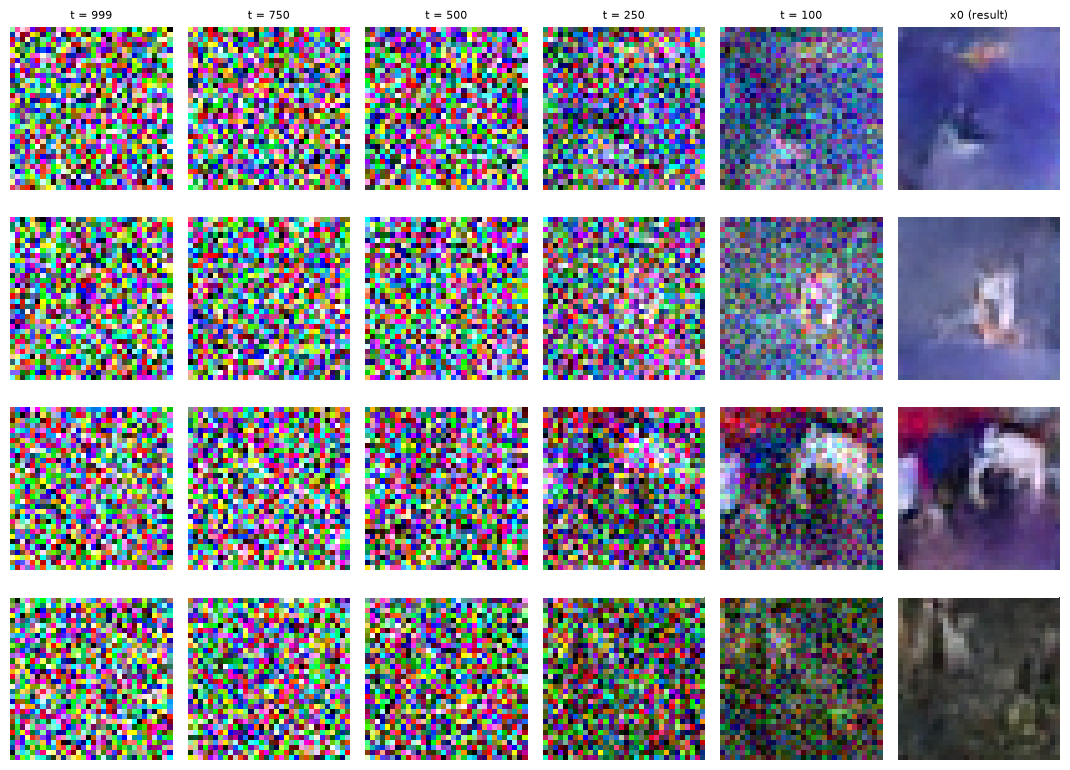

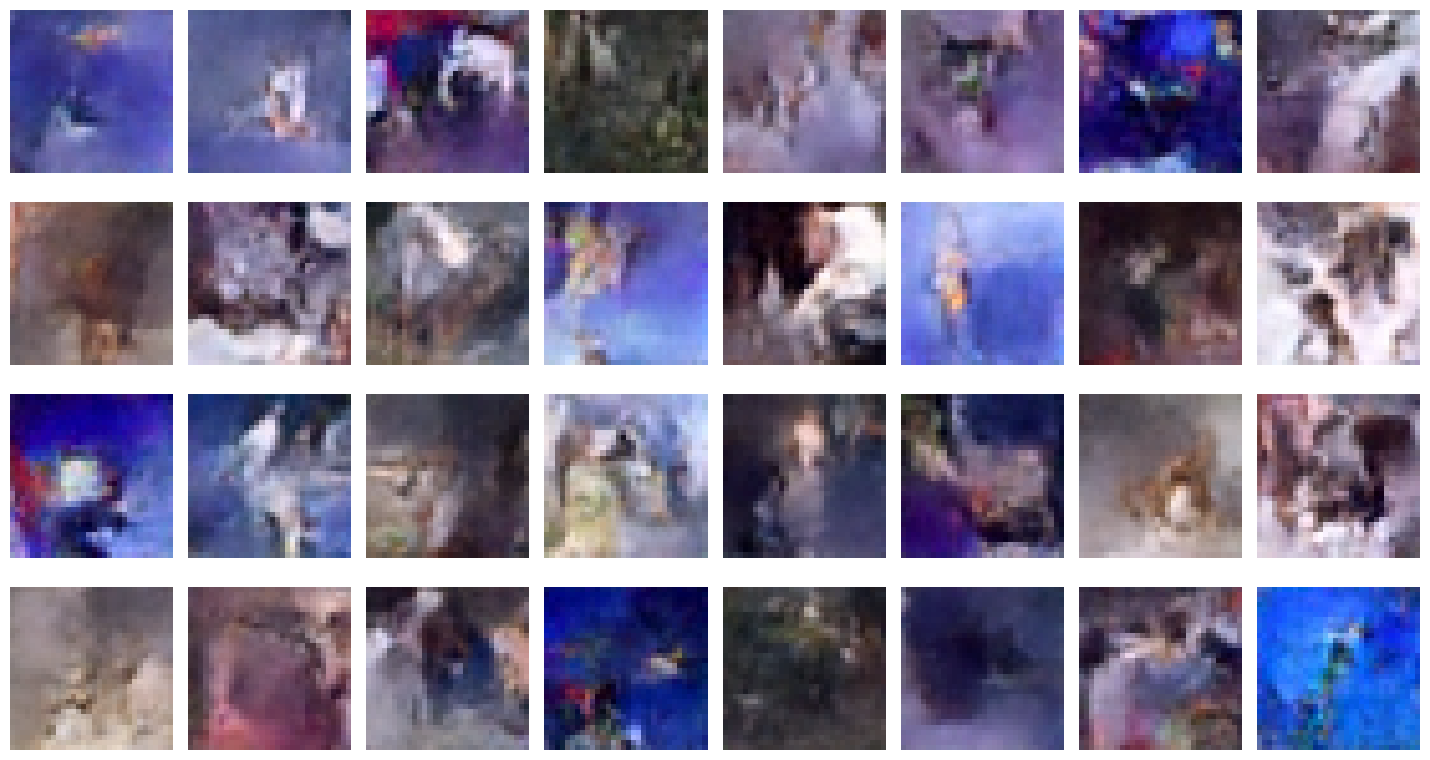

In [9]:
generation_z = torch.randn(NUM_GENERATED, *IMAGE_SHAPE, generator=torch.Generator().manual_seed(SEED + 3))

start = time.perf_counter()
generation_states, generated = reverse_chain(
    task.schedule, generation_z.to(device), STEPS - 1, model_eps(task.model), torch.Generator().manual_seed(SEED + 3)
)
generation_seconds = time.perf_counter() - start

stages = torch.stack([*(generation_states[t] for t in CHAIN_STEPS), generated], dim=1)[:GENERATION_SHOWN].flatten(0, 1)
stage_titles = chain_titles + [""] * (len(stages) - len(chain_titles))
saver.save(plot_image_grid(to_display(stages), stage_titles, ncols=len(chain_titles)), "generation_stages")
saver.save(plot_image_grid(to_display(generated), ncols=8), "generated")

print(f"Generated {NUM_GENERATED} images in {generation_seconds:.1f}s | {STEPS} U-Net passes per image")

mse                                        psnr  \
method full chain x0_hat noisy x_t one-step x0_hat full chain x0_hat   
t                                                                      
100               0.0053    0.0239          0.0028           22.8935   
250               0.0154    0.0926          0.0083           18.3147   
500               0.0408    0.1633          0.0244           14.1077   
750               0.0892    0.1853          0.0846           10.8711   

                                              ssim                            
method noisy x_t one-step x0_hat full chain x0_hat noisy x_t one-step x0_hat  
t                                                                             
100      16.2276         25.6607            0.7033    0.3928          0.8103  
250      10.3335         21.0135            0.4434    0.1365          0.5912  
500       7.9034         16.4183            0.1897    0.0372          0.2809  
750       7.3758         11.0126            0.0895    0.0123          0.0384

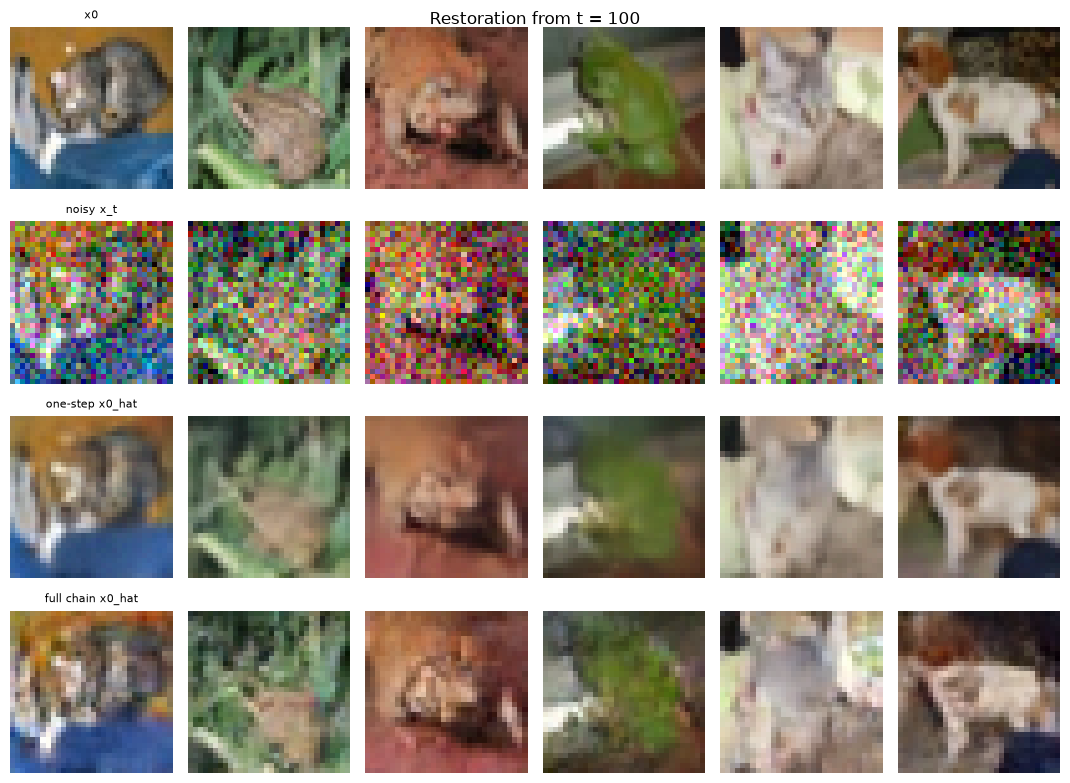

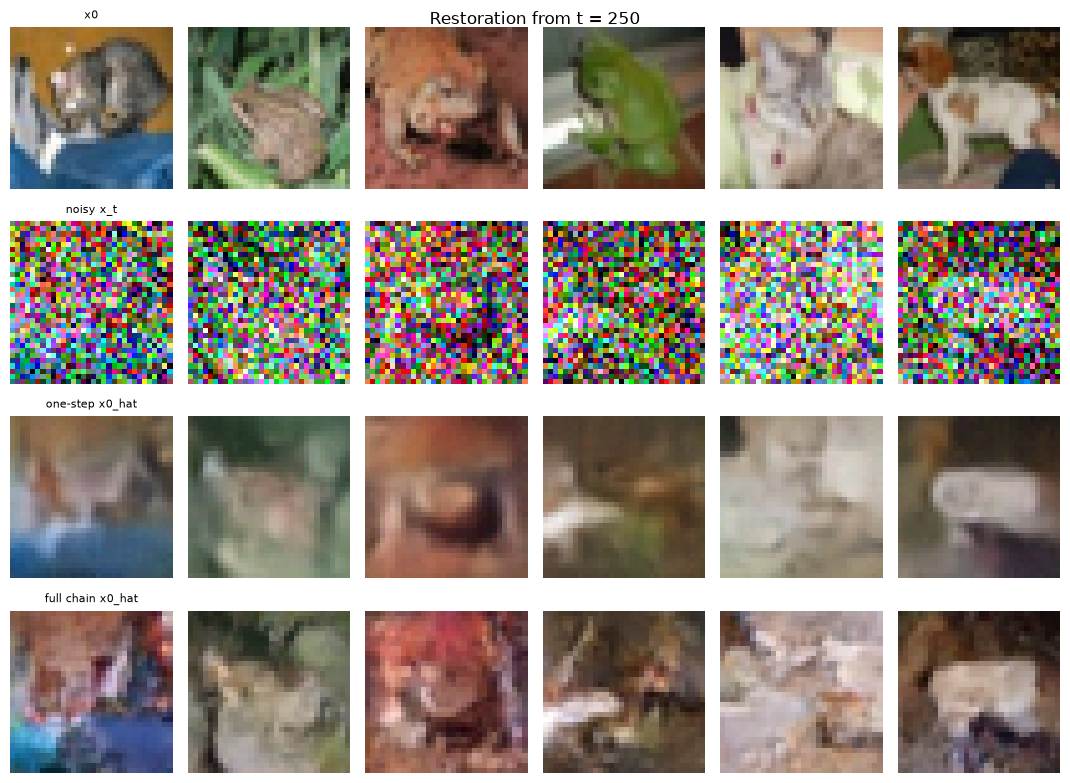

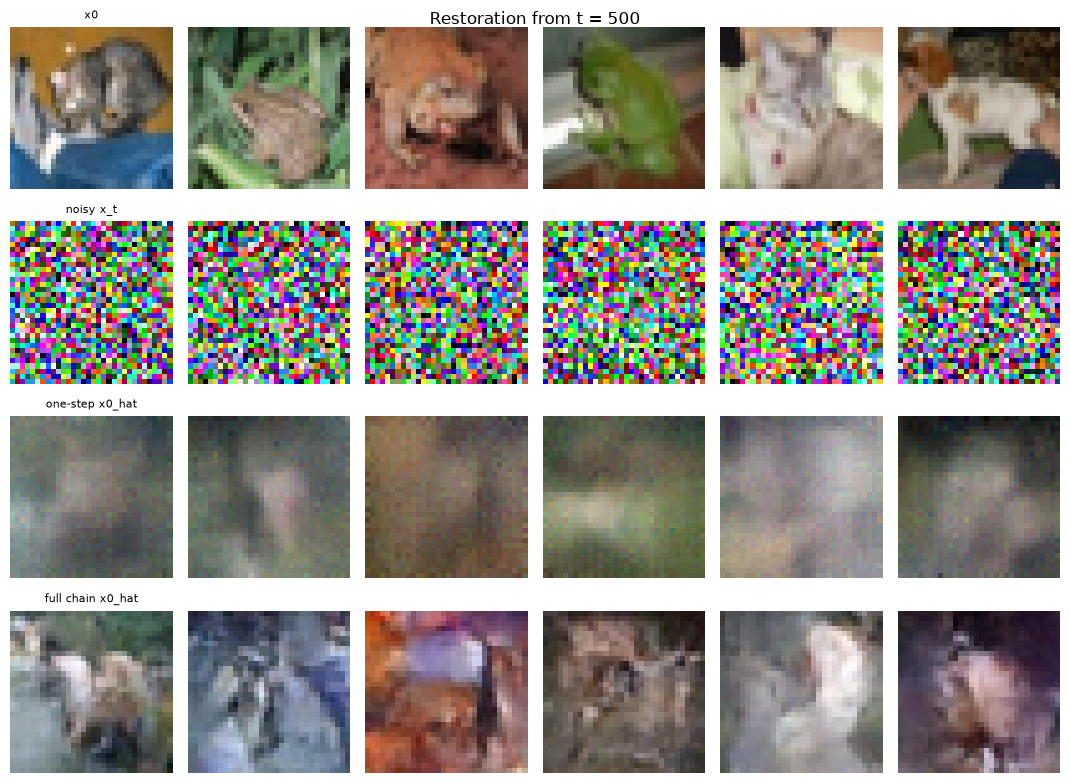

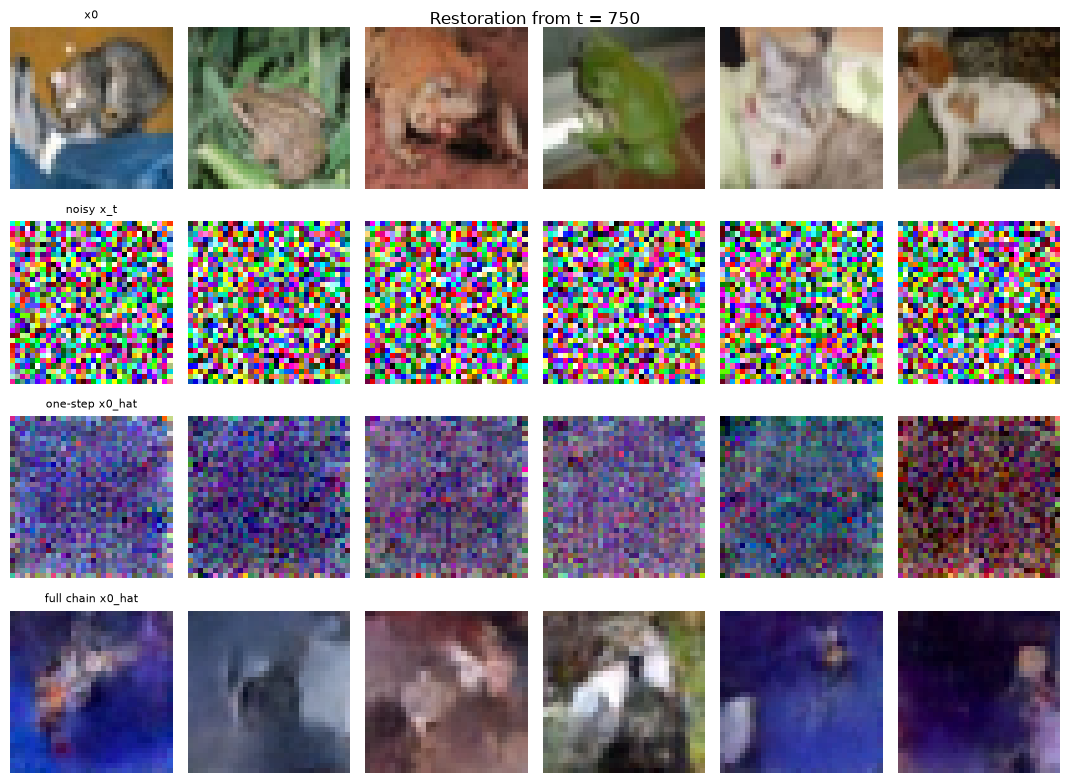

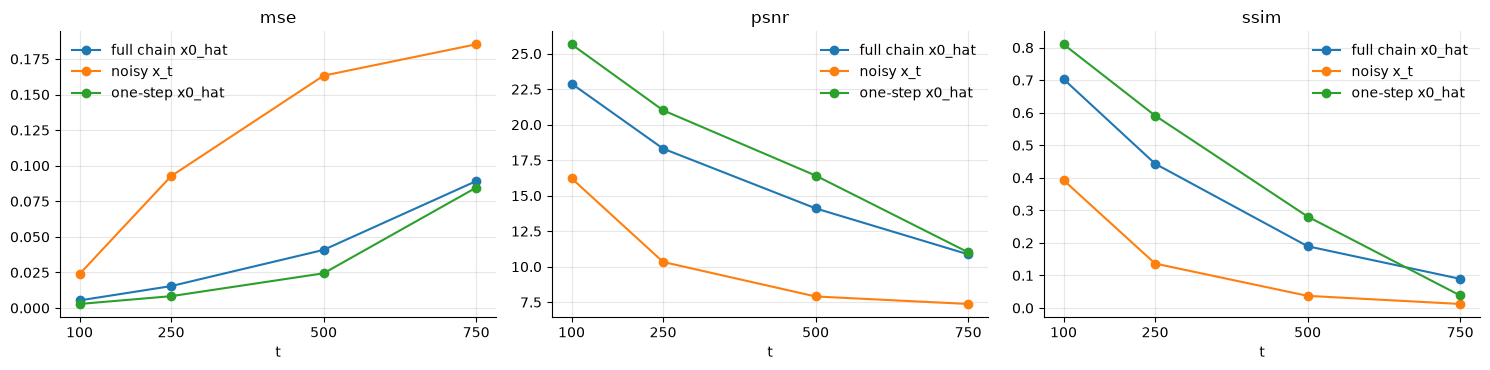

In [10]:
def image_scores(preds: torch.Tensor, target: torch.Tensor) -> dict[str, float]:
    metrics = image_metrics()
    metrics.update(preds, target)
    return {name: float(value) for name, value in metrics.compute().items()}


eval_images = test_images[:RESTORE_EVAL].to(device)
eval_target = to_display(eval_images)
predict = model_eps(task.model)

records = []
for step in RESTORE_STEPS:
    generator = torch.Generator().manual_seed(SEED + step)
    steps = torch.full((len(eval_images),), step, device=device)
    x_t = task.schedule.add_noise(eval_images, steps, torch.randn(eval_images.shape, generator=generator).to(device))
    one_step = task.schedule.predict_x0(x_t, steps, predict(x_t, step)).clamp(-1, 1)
    _, chain = reverse_chain(task.schedule, x_t, step, predict, generator)

    outputs = {"noisy x_t": x_t, "one-step x0_hat": one_step, "full chain x0_hat": chain}
    for method, images in outputs.items():
        records.append({"t": step, "method": method} | image_scores(to_display(images), eval_target))

    shown = torch.cat([eval_images[:RESTORE_SHOWN], *(images[:RESTORE_SHOWN] for images in outputs.values())])
    titles = [name if column == 0 else "" for name in ["x0", *outputs] for column in range(RESTORE_SHOWN)]
    fig = plot_image_grid(to_display(shown), titles, ncols=RESTORE_SHOWN)
    fig.suptitle(f"Restoration from t = {step}")
    saver.save(fig, f"restore_t{step:03d}")

restoration = pd.DataFrame(records).pivot(index="t", columns="method", values=["mse", "psnr", "ssim"])
restoration.to_csv(saver.directory / "restoration.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["mse", "psnr", "ssim"]):
    for method in restoration[metric].columns:
        ax.plot(RESTORE_STEPS, restoration[metric][method], marker="o", label=method)
    ax.set_xticks(RESTORE_STEPS)
    ax.set_xlabel("t")
    ax.set_title(metric)
    ax.legend()
fig.tight_layout()
saver.save(fig, "restoration_metrics")

restoration.round(4)